In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

from bioio import BioImage

import prrt_clustering as pclst

# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")
channels = ["PRRT", "A1", "PSD", "RIM"]
data_path = Path(
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/Experiment-358.czi"
)
image = BioImage(data_path)
data = image.xarray_dask_data.assign_coords({"C": channels})

In [ ]:
import napari

v = napari.Viewer()
v.add_image(image.data, channel_axis=1, name=channels)

# 2. Drift correction

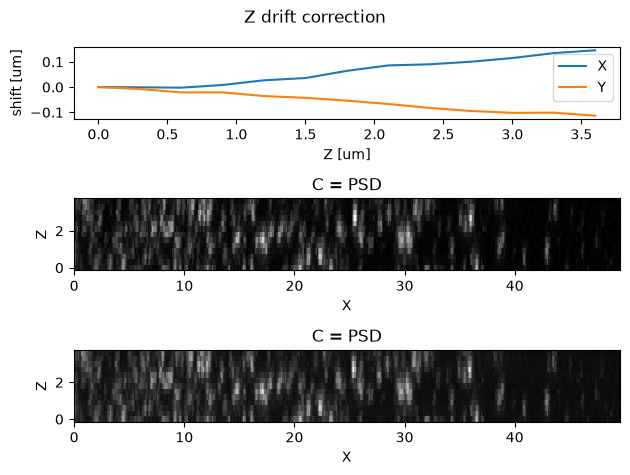

In [3]:
shifts, stabilized = pclst.correct_z_drift(data)
pclst.plot_drift_correction(data,stabilized,shifts)

In [ ]:
# v.add_image(stabilized.data[0,0,:,:100,:100], channel_axis=1)

## 3. Spot detection

- Detect spots in all channels

(<Figure size 2000x2000 with 4 Axes>,
 {'A1': <Axes: title={'center': 'A1'}>,
  'PRRT': <Axes: title={'center': 'PRRT'}>,
  'PSD': <Axes: title={'center': 'PSD'}>,
  'RIM': <Axes: title={'center': 'RIM'}>})

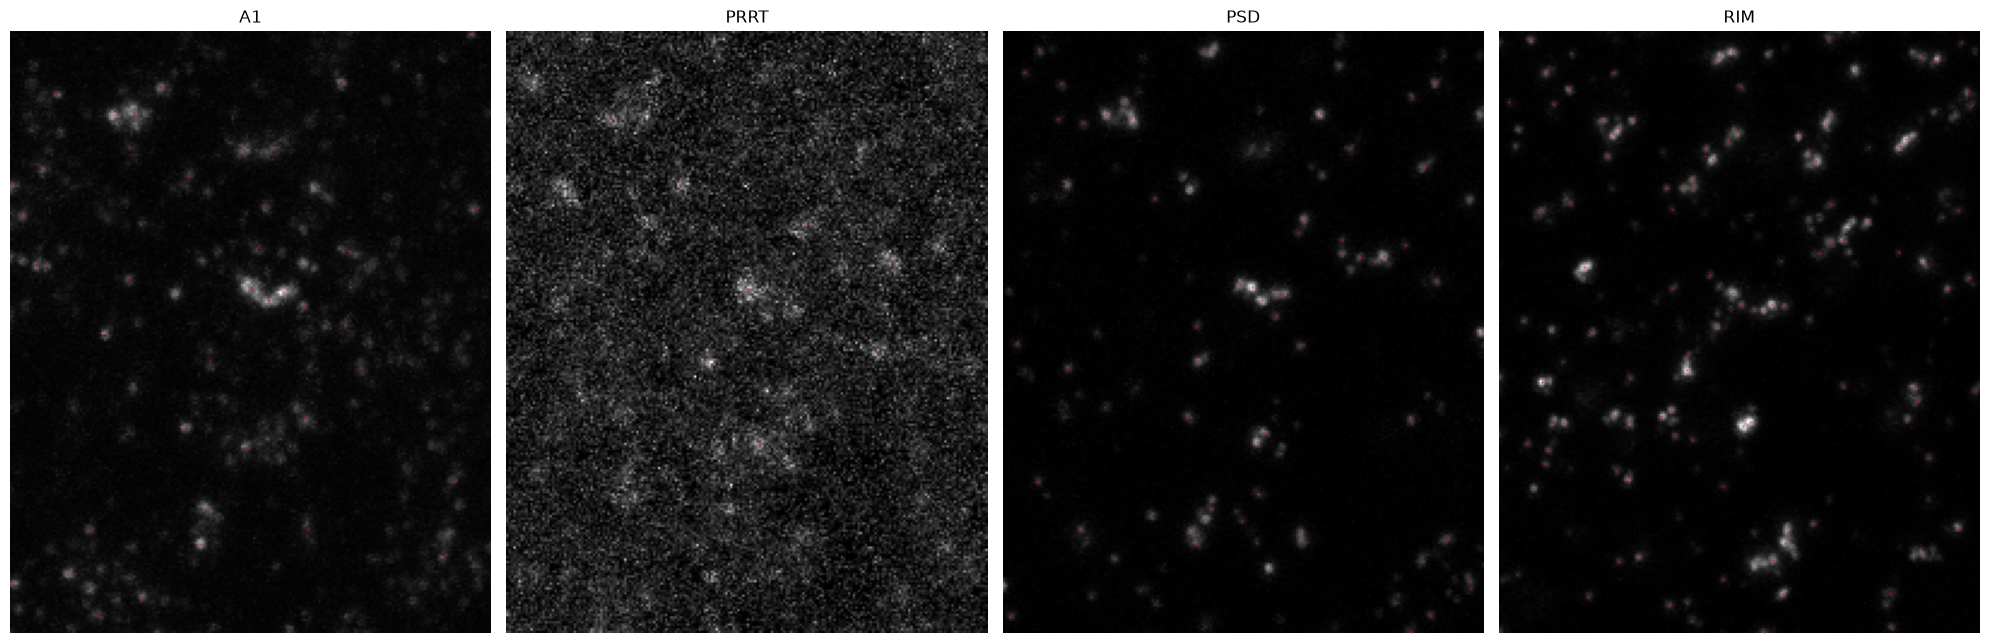

In [4]:
import matplotlib.pyplot as plt
import numpy as np

tmp = stabilized[0, :, :, 250:500, 800:1000]
parameters = {
    "PRRT": {"scale_um": 0.4, "specificity": 6},
    "A1": {"scale_um": 0.3, "specificity": 6},
    "PSD": {"scale_um": 0.1, "specificity": 8},
    "RIM": {"scale_um": 0.1, "specificity": 6},
}

points = pclst.detect_puncta(tmp, parameters)

fig = plt.figure(figsize=(20, 20))
fig, axes = pclst.plot_data(tmp, split=True, fig=fig)
pclst.plot_points(points, ms=1, split=True, axes_dict=axes)


In [ ]:
import napari

v = napari.Viewer(ndisplay=3)
# v.add_image(image.data, channel_axis=1)
vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
# v.add_image(tmp,scale=vx,translate=o, channel_axis=0,name=channels)
fcol = {"PRRT": "magenta", "A1": "red", "PSD": "green", "RIM": "yellow"}
for n, pts in points.groupby("C"):
    v.add_image(tmp.sel(C=n), scale=vx, translate=o, name=n, colormap=fcol[n])
    v.add_points(pts[["Z", "Y", "X"]], size=0.5, name=n, face_color=fcol[n])

## 3. Clustering of RIM and PSD channels
Cluster points to identify potential synapses.

--


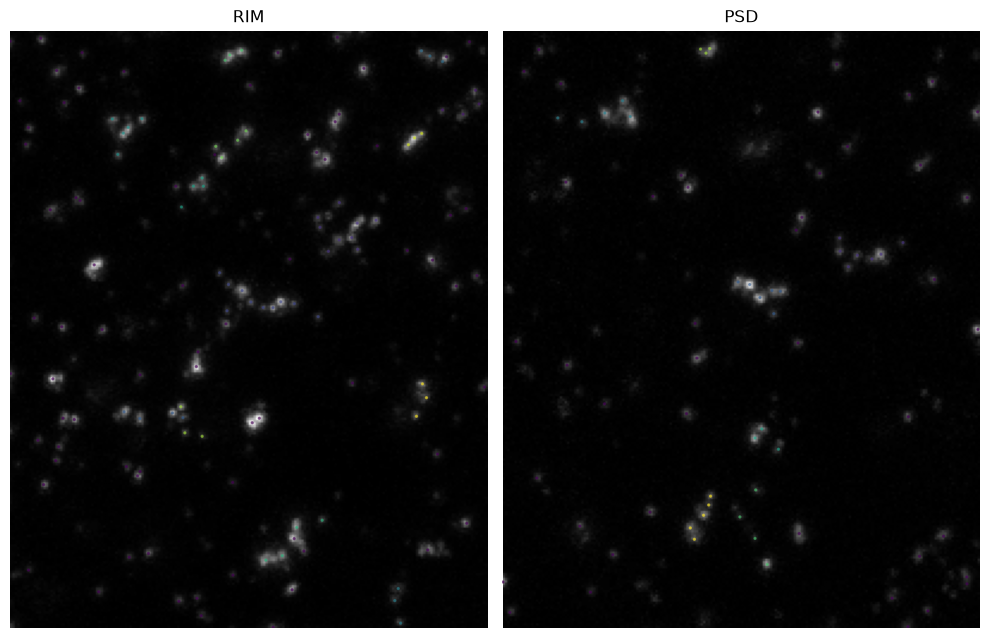

In [6]:

points, clusters = pclst.cluster_dbscan(points, ["RIM","PSD"], eps=1.5, min_samples=3)
# pvalues_cluster = compute_dbscan_clustering_pvalue(points,["RIM","PSD"], eps=1.5, min_samples=3)

fig = plt.figure(figsize=(10, 10))
fig, axes = pclst.plot_data(tmp.sel(C=["RIM", "PSD"]), split=True, fig=fig)
for n, g in points[points["C"].isin(["RIM", "PSD"])].groupby("C"):
    axes[n].scatter(g["X"], g["Y"], c=g["cluster_id"], s=2,alpha=0.5)


## 4. Pre-post synaptic cluster association
Identify synapses as pair of cluster

number of paired clusters :  5


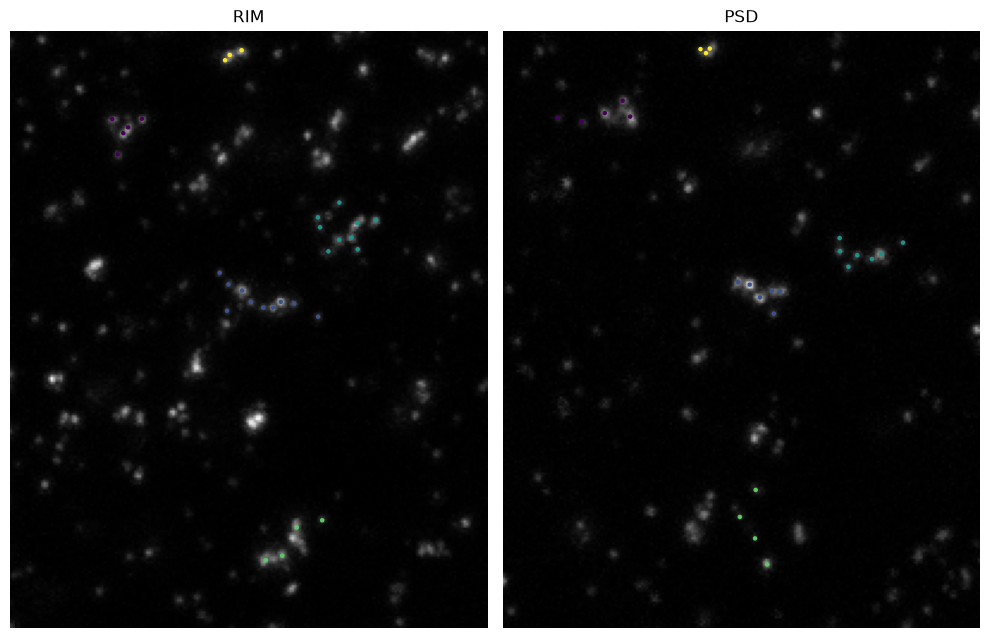

In [7]:

points, synapses = pclst.pair_cluster(points, ["PSD", "RIM"], distance=1)

fig = plt.figure(figsize=(10, 10))
fig, axes = pclst.plot_data(tmp.sel(C=["RIM", "PSD"]), split=True, fig=fig)
for n, g in points[points["synapse_id"] >= 0].groupby("C"):
    axes[n].scatter(g["X"], g["Y"], c=g["synapse_id"], s=5)

print("number of paired clusters : ", len(synapses))

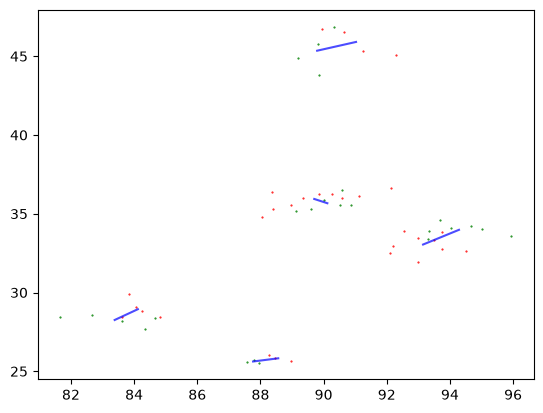

In [9]:

for n, g in points[points["synapse_id"] >= 0].groupby("synapse_id"):
    g1 = g[g["C"]=="RIM"]
    g2 = g[g["C"]=="PSD"]
    c1 = g1[["X","Y"]].mean(axis=0)
    c2 = g2[["X","Y"]].mean(axis=0)
    plt.plot(g1["X"], g1["Y"], 'ro',ms=0.5)
    plt.plot(g2["X"], g2["Y"], 'go',ms=0.5)
    plt.plot([c1["X"],c2["X"]],[c1["Y"],c2["Y"]],'b-',alpha=0.7)

## 5. Identify pair of A1-PRRT

Identify pair of A1-PRRT puncta


In [ ]:
points, pairs = pclst.pair_puncta(points, ["A1", "PRRT"], distance=10)

## 6. Synapse profiling

For each synapse, associate the puncate in all channel


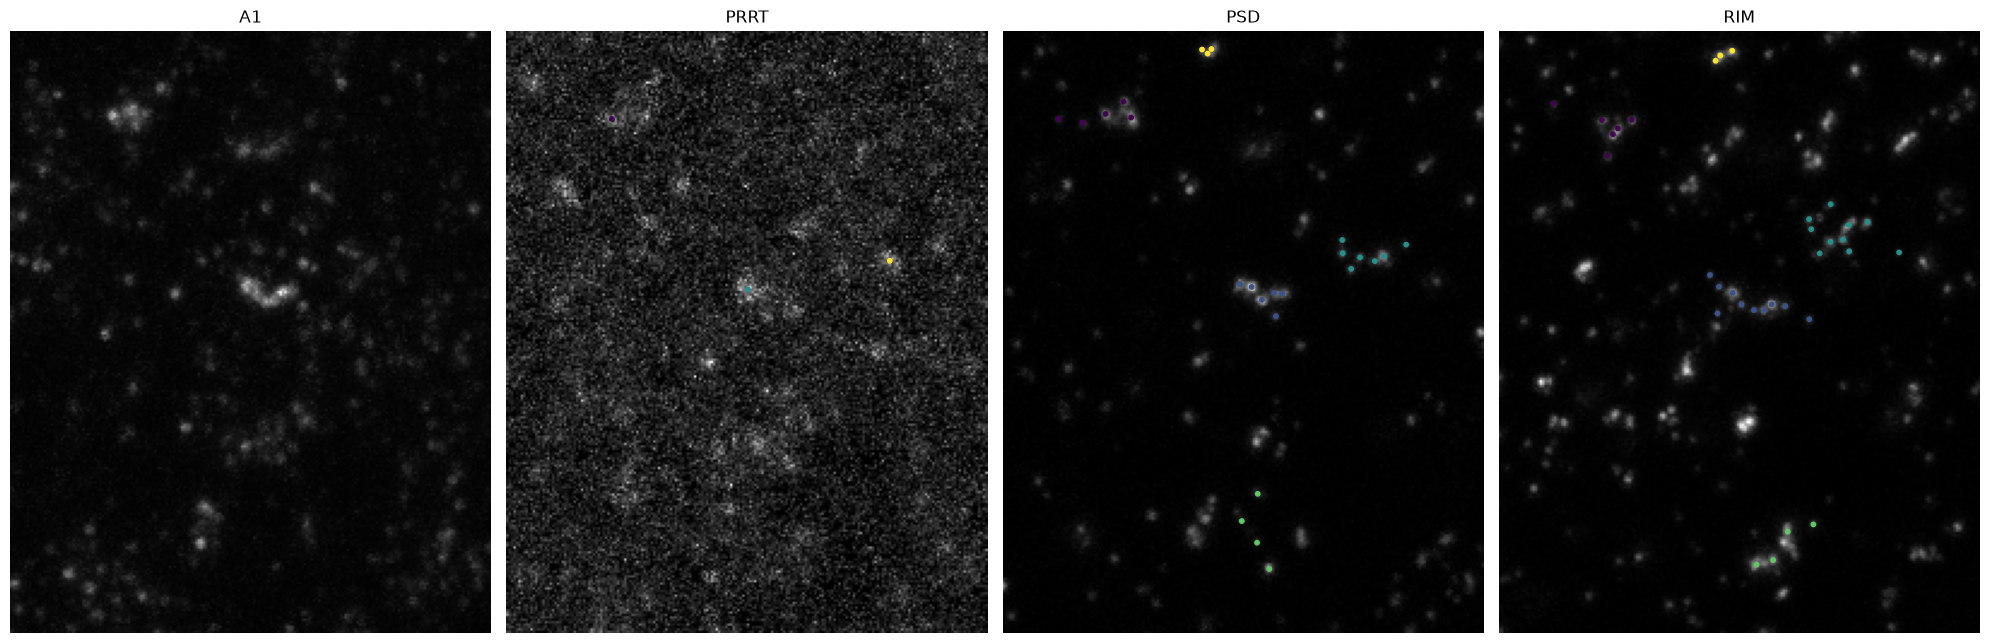

In [ ]:


points = pclst.associate_to_paired_cluster(points,["PRRT","A1"], 1)
points = pclst.compute_distances(points)

fig = plt.figure(figsize=(20, 20))
fig, axes = pclst.plot_data(tmp, split=True, fig=fig)
for n, g in points.groupby("C"):
    g=g[g["synapse_id"]>=0]
    axes[n].scatter(g["X"], g["Y"], c=g["synapse_id"], s=10)


Extract statistics

In [ ]:
gst = pclst.global_stats(points, 1, 2., 1)
sst = pclst.synapse_stats(points)

ok 1
ok 2


KeyError: "None of [Index([33, 33, 33, 1, 33, 26, 7, 6, 1, 33, 0, 33, 33], dtype='int64')] are in the [columns]"

Make figure

In [ ]:
from prrt_clustering.plot import make_the_bagel_plot

make_the_bagel_plot(gst,sst)

In [ ]:
from prrt_clustering.plot import make_the_histogram_distance

make_the_histogram_distance(points)